<a href="https://colab.research.google.com/github/inorganicnoise/KLASIFIKASI-SAMPAH-TRANSFER-LEARNING/blob/main/Klasifikasi_Sampah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Klasifikasi Jenis Sampah Menggunakan Transfer Learning (MobileNetV2)**

### ♻️ Project Deep Learning - SDGs 12: Konsumsi dan Produksi yang Bertanggung Jawab

Notebook ini berisi implementasi **Transfer Learning berbasis Convolutional Neural Network (CNN)** menggunakan **TensorFlow/Keras** untuk mengklasifikasikan jenis sampah berdasarkan citra gambar, sebagai pendukung pemilahan sampah di lingkungan kampus.

**Anggota Kelompok**

| No. | Nama | NIM |
|---|---|---|
| 1 | Elsya Sagitha Damayanti S | F1G125029 |
| 2 | Rahmah Hidayah Lahompu | F1G125047 |
| 3 | Ridha Septiani K | F1G125075 |

Program Studi Ilmu Komputer, FMIPA, Universitas Halu Oleo

**Sumber Data:** [RealWaste - Kaggle](https://www.kaggle.com/datasets/joebeachcapital/realwaste)

## **1. Pengumpulan Dataset**

Dataset yang digunakan adalah **RealWaste** dari Kaggle, berisi 4.752 gambar RGB (524 × 524 piksel) dalam 9 kategori sampah: Cardboard, Food Organics, Glass, Metal, Miscellaneous Trash, Paper, Plastic, Textile Trash, dan Vegetation. Dataset diunduh langsung menggunakan `kagglehub`.

In [1]:
import kagglehub

dataset_path = kagglehub.dataset_download('joebeachcapital/realwaste')

Using Colab cache for faster access to the 'realwaste' dataset.


In [2]:
import os

dataset_folder = os.path.join(dataset_path,'realwaste-main', 'RealWaste')

for item in os.listdir(dataset_folder):
  print(item)

Metal
Glass
Paper
Vegetation
Cardboard
Textile Trash
Food Organics
Plastic
Miscellaneous Trash


## **2. Exploratory Data Analysis (EDA)**

Tahap eksplorasi untuk memahami struktur folder, jumlah gambar pada setiap kategori, dan distribusi kelas. Distribusi kelas perlu diperhatikan karena jumlah gambar antar kategori tidak seimbang (misalnya Plastic 921 gambar vs Textile Trash 318 gambar).

In [3]:
for kategori in os.listdir(dataset_folder):
    print(kategori, ":", len(os.listdir(os.path.join(dataset_folder, kategori))))

Metal : 790
Glass : 420
Paper : 500
Vegetation : 436
Cardboard : 461
Textile Trash : 318
Food Organics : 411
Plastic : 921
Miscellaneous Trash : 495


### Visualisasi Sampel Gambar

Menampilkan satu contoh gambar dari setiap kategori untuk melihat karakteristik visual masing-masing jenis sampah.

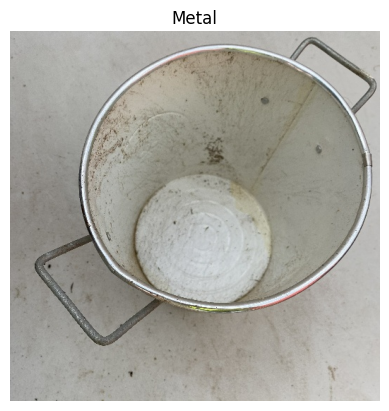

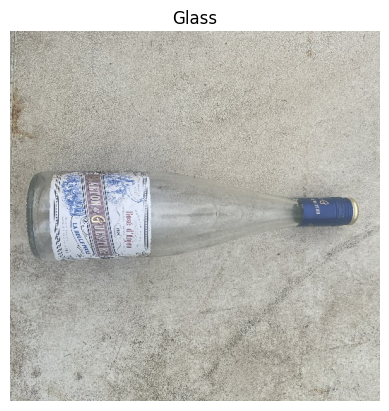

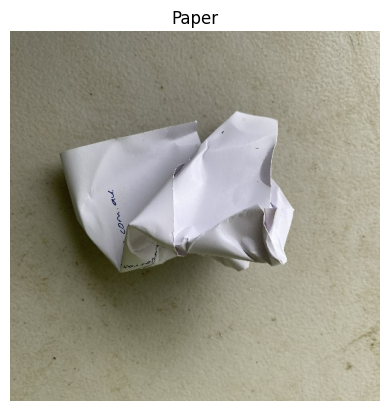

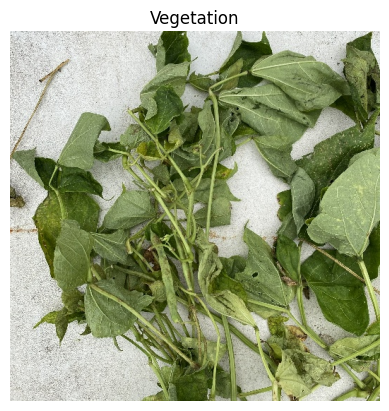

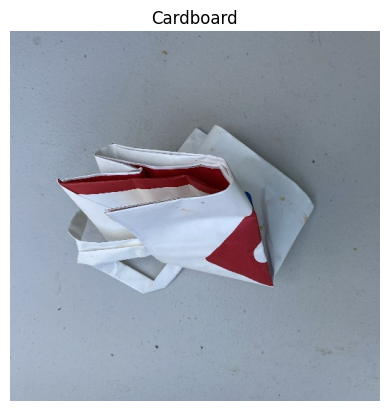

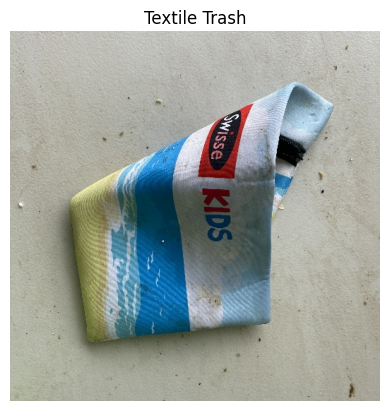

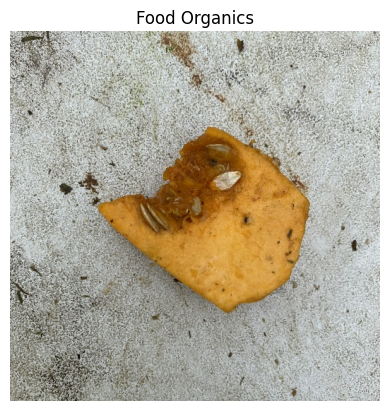

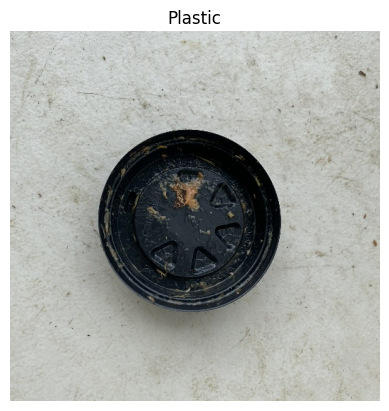

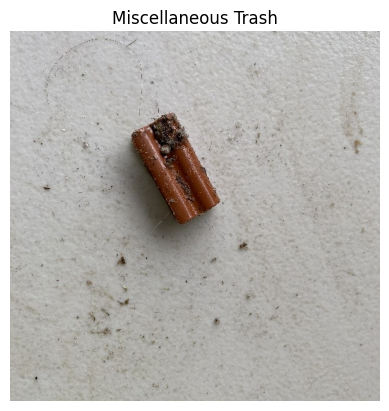

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

for kategori in os.listdir(dataset_folder):
  gambar = os.listdir(os.path.join(dataset_folder, kategori))[0]
  img = Image.open(os.path.join(dataset_folder, kategori, gambar))

  plt.imshow(img)
  plt.title(kategori)
  plt.axis('off')
  plt.show()

## **3. Pembagian Dataset**

Dataset dibagi menjadi tiga bagian menggunakan library `split-folders` dengan `seed=42` agar hasil pembagian dapat direproduksi:

| Bagian | Proporsi | Fungsi |
|---|---|---|
| Training Set | 70% | Melatih model |
| Validation Set | 15% | Memantau proses pelatihan |
| Testing Set | 15% | Menguji performa akhir model |

In [5]:
!pip install -q split-folders

In [6]:
import splitfolders

splitfolders.ratio(
    dataset_folder,
    output="dataset_split",
    seed=42,
    ratio=(0.7, 0.15, 0.15)
)

Copying files: 4752 files [00:35, 133.20 files/s]


### Pemeriksaan Hasil Pembagian

Memastikan jumlah gambar pada setiap bagian (train, val, test) sudah sesuai dengan proporsi yang ditentukan.

In [7]:
for bagian in ['train', 'val', 'test']:
  print(bagian, ': ', sum(len(os.listdir(os.path.join("dataset_split", bagian, k))) for k in os.listdir(os.path.join("dataset_split", bagian)) ))

train :  3323
val :  710
test :  719


## **4. Preprocessing Data**

### Memuat Dataset

Gambar dimuat dari folder menggunakan `image_dataset_from_directory` dengan ukuran **224 × 224 piksel** (sesuai input MobileNetV2) dan *batch size* 32. Label kelas diambil otomatis dari nama folder. Data validasi dan testing tidak diacak (`shuffle=False`) agar urutan label konsisten saat evaluasi.

In [8]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/train",
    image_size=(224, 224),
    batch_size=32
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/val",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_split/test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

Found 3323 files belonging to 9 classes.
Found 710 files belonging to 9 classes.
Found 719 files belonging to 9 classes.


In [9]:
print(train_ds.class_names)

['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


### Normalisasi Piksel

Nilai piksel dinormalisasi menggunakan `preprocess_input` bawaan MobileNetV2, yang mengubah rentang piksel dari [0, 255] menjadi **[-1, 1]** agar sesuai dengan cara model *pre-trained* dilatih sebelumnya.

In [10]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

train_ds= train_ds.map(lambda x,y : (preprocess_input(x), y))
val_ds= val_ds.map(lambda x,y : (preprocess_input(x), y))
test_ds= test_ds.map(lambda x,y : (preprocess_input(x), y))

Pengecekan nilai minimum dan maksimum untuk memastikan normalisasi berhasil.

In [11]:
for image, label in train_ds.take(1):
  print('nilai minimum: ', tf.reduce_min(image).numpy())
  print('nilai maksimum: ', tf.reduce_max(image).numpy())

nilai minimum:  -1.0
nilai maksimum:  1.0


# **Pemodelan**

## **5. Implementasi Transfer Learning**

Model dasar yang digunakan adalah **MobileNetV2** dengan bobot *pre-trained* dari **ImageNet**. Bagian klasifikasi bawaan (`include_top=False`) dibuang, lalu bobot model dasar dibekukan (`trainable=False`) sehingga hanya lapisan klasifikasi baru yang dilatih.

In [12]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape = (224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable=False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Arsitektur Model

Lapisan klasifikasi baru ditambahkan di atas MobileNetV2:

| Lapisan | Fungsi |
|---|---|
| MobileNetV2 (frozen) | Ekstraksi fitur visual |
| GlobalAveragePooling2D | Meringkas *feature map* menjadi satu vektor fitur |
| Dropout (0.2) | Mengurangi risiko *overfitting* |
| Dense (9, softmax) | Menghasilkan probabilitas untuk 9 kategori sampah |

In [13]:
model = tf.keras.Sequential ([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(9, activation='softmax')
])

### Kompilasi Model

- **Optimizer:** Adam
- **Loss function:** Sparse Categorical Crossentropy (label berupa bilangan bulat)
- **Metrik:** Accuracy

In [14]:
model.compile(
    optimizer ='adam',
    loss = 'sparse_categorical_crossentropy',
    metrics= ['accuracy']
)

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## **6. Training Model**

Model dilatih selama **10 epoch** menggunakan data training, dengan data validasi untuk memantau performa pada setiap epoch.

In [16]:
history = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 10
)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 68s 417ms/step - accuracy: 0.5152 - loss: 1.3978 - val_accuracy: 0.6690 - val_loss: 0.8889
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - accuracy: 0.7195 - loss: 0.7890 - val_accuracy: 0.7310 - val_loss: 0.7377
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 22s 125ms/step - accuracy: 0.7734 - loss: 0.6458 - val_accuracy: 0.7592 - val_loss: 0.6870
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 11s 102ms/step - accuracy: 0.7999 - loss: 0.5702 - val_accuracy: 0.7831 - val_loss: 0.6356
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 22s 113ms/step - accuracy: 0.8300 - loss: 0.4966 - val_accuracy: 0.7901 - val_loss: 0.6148
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - accuracy: 0.8492 - loss: 0.4581 - val_accuracy: 0.7958 - val_loss: 0.6056
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - accuracy: 0.8553 - loss: 0.4265 - val_accuracy: 0.7887 - val_loss: 0.5853
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 11s 104ms/step - accuracy: 0.8640 - loss: 0

# **Evaluasi Model**

## **7. Evaluasi pada Data Testing**

Model diuji pada data testing yang tidak digunakan selama pelatihan untuk mengetahui akurasi dan loss akhir.

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

23/23 ━━━━━━━━━━━━━━━━━━━━ 17s 757ms/step - accuracy: 0.8192 - loss: 0.5330
Test Accuracy: 0.8191933035850525
Test Loss: 0.532990038394928


### Classification Report

Menampilkan **precision**, **recall**, dan **F1-score** untuk setiap kategori sampah.

- **Precision:** ketepatan prediksi pada suatu kategori.
- **Recall:** kemampuan model mengenali seluruh data pada suatu kategori.
- **F1-score:** keseimbangan antara precision dan recall.

In [18]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

class_names = sorted(os.listdir("dataset_split/train"))

print(classification_report(y_true, y_pred, target_names=class_names))

23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 200ms/step
                     precision    recall  f1-score   support

          Cardboard       0.79      0.91      0.85        70
      Food Organics       0.81      0.97      0.88        63
              Glass       0.86      0.78      0.82        63
              Metal       0.72      0.92      0.81       119
Miscellaneous Trash       0.76      0.59      0.66        75
              Paper       0.87      0.79      0.83        75
            Plastic       0.83      0.70      0.76       139
      Textile Trash       0.93      0.86      0.89        49
         Vegetation       0.95      0.95      0.95        66

           accuracy                           0.82       719
          macro avg       0.84      0.83      0.83       719
       weighted avg       0.82      0.82      0.82       719



### Confusion Matrix

Membandingkan label sebenarnya dengan hasil prediksi model. Dari sini terlihat kategori mana yang sering salah diklasifikasikan.

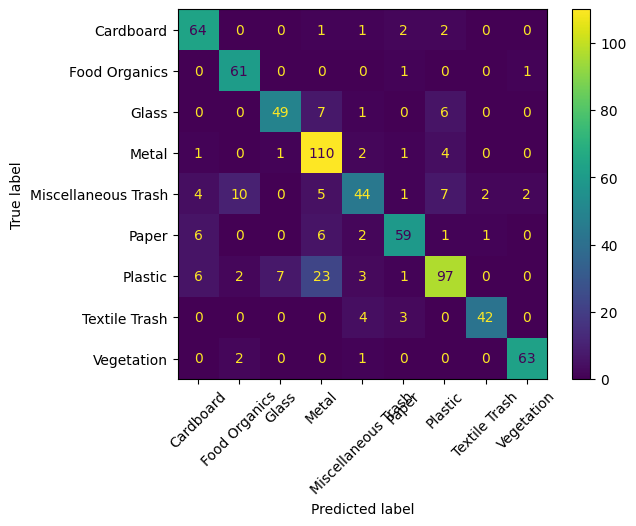

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    xticks_rotation=45
)

plt.show()

### Grafik Accuracy dan Loss

Visualisasi akurasi dan loss pada data training dan validasi di setiap epoch untuk melihat apakah model sudah belajar dengan baik atau terindikasi *overfitting*.

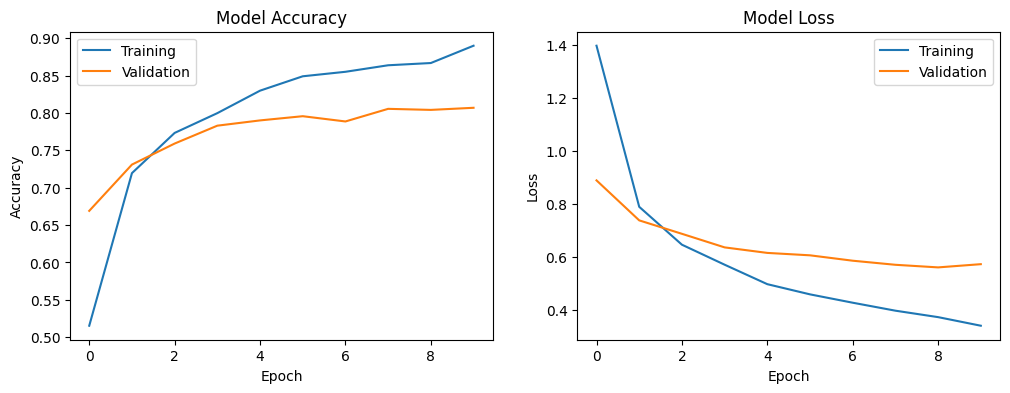

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

## **8. Fine-Tuning Model**

Proses pelatihan ulang model dengan membuka 30 lapisan terakhir MobileNetV2 agar dapat menyesuaikan bobot model dengan dataset RealWaste.

In [21]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Training Fine-Tuning

Model dilatih kembali menggunakan data training dan validation selama 15 epoch dengan learning rate sebesar 0,00001.

In [22]:
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 37s 235ms/step - accuracy: 0.9007 - loss: 0.3039 - val_accuracy: 0.8155 - val_loss: 0.5569
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 11s 104ms/step - accuracy: 0.9142 - loss: 0.2543 - val_accuracy: 0.8197 - val_loss: 0.5230
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 10s 92ms/step - accuracy: 0.9299 - loss: 0.2153 - val_accuracy: 0.8324 - val_loss: 0.5280
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - accuracy: 0.9449 - loss: 0.1869 - val_accuracy: 0.8254 - val_loss: 0.5030
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - accuracy: 0.9540 - loss: 0.1604 - val_accuracy: 0.8268 - val_loss: 0.5023
Epoch 6/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step - accuracy: 0.9609 - loss: 0.1387 - val_accuracy: 0.8394 - val_loss: 0.4981
Epoch 7/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - accuracy: 0.9729 - loss: 0.1149 - val_accuracy: 0.8296 - val_loss: 0.4973
Epoch 8/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 11s 104ms/step - accuracy: 0.9750 - loss: 0.

## **9. Evaluasi Setelah Fine-Tuning**

Model diuji kembali menggunakan data testing untuk mengetahui performa setelah proses fine-tuning.

In [23]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 174ms/step - accuracy: 0.8595 - loss: 0.4567
Test Loss: 0.45673686265945435
Test Accuracy: 0.8595271110534668


## Classification Report

Menampilkan nilai precision, recall, dan F1-score untuk mengetahui ketepatan klasifikasi pada setiap kategori sampah.

In [24]:
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

class_names = sorted(os.listdir("dataset_split/train"))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
                     precision    recall  f1-score   support

          Cardboard       0.83      0.89      0.86        70
 

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

## Confusion Matrix

Menampilkan perbandingan antara label sebenarnya dan hasil prediksi model untuk mengetahui kategori sampah yang berhasil dan salah diklasifikasikan.

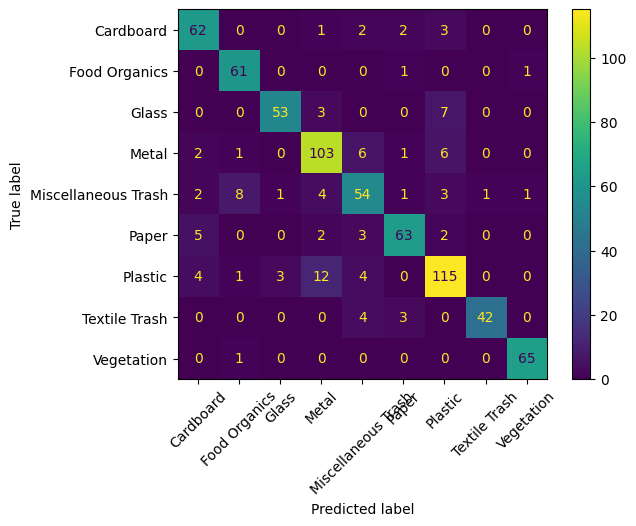

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    xticks_rotation=45
)

plt.show()

## Perbandingan Hasil Training

Membandingkan nilai accuracy dan loss antara training awal dengan fine-tuning untuk melihat perubahan performa model setelah proses pelatihan ulang.

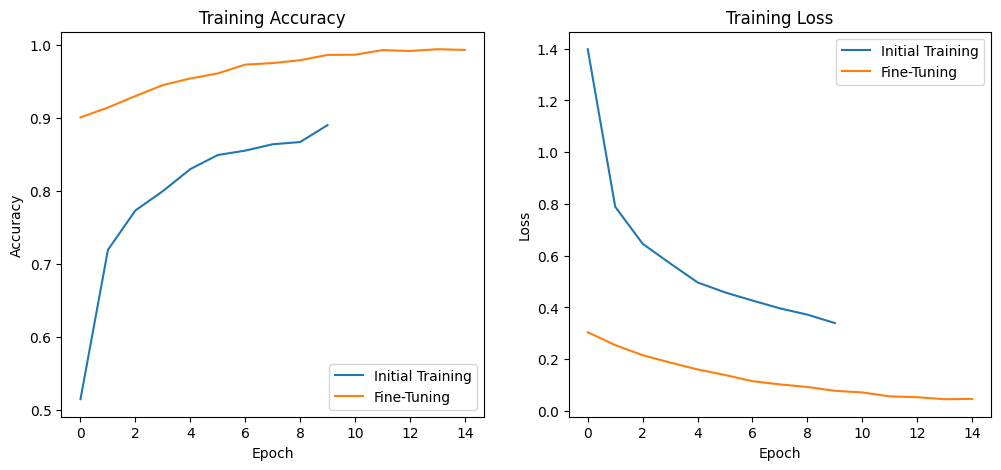

In [27]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Initial Training")
plt.plot(history_fine.history["accuracy"], label="Fine-Tuning")
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Initial Training")
plt.plot(history_fine.history["loss"], label="Fine-Tuning")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

## Ringkasan Hasil Evaluasi Akhir

Menampilkan hasil evaluasi akhir model berdasarkan nilai accuracy, precision, recall, dan F1-score untuk mengetahui kemampuan model dalam mengklasifikasikan sembilan kategori sampah.

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("RINGKASAN HASIL EVALUASI AKHIR")
print("--------------------------------")

print("Accuracy  :", accuracy_score(y_true, y_pred))
print("Precision :", precision_score(y_true, y_pred, average="weighted"))
print("Recall    :", recall_score(y_true, y_pred, average="weighted"))
print("F1-Score  :", f1_score(y_true, y_pred, average="weighted"))

RINGKASAN HASIL EVALUASI AKHIR
--------------------------------
Accuracy  : 0.8595271210013908
Precision : 0.8613803093643397
Recall    : 0.8595271210013908
F1-Score  : 0.8593509410645498


# **10. Penyimpanan Model**

## Menyimpan Model

Menyimpan model hasil fine-tuning dalam format `.keras` agar dapat digunakan kembali tanpa mengulangi proses pelatihan.

In [29]:
model.save("waste_classifier.keras")

## Menyimpan Nama Kelas

Menyimpan nama kategori sampah dalam format JSON sebagai label yang digunakan dalam proses prediksi.

In [30]:
import json

class_names = sorted(os.listdir("dataset_split/train"))

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

# 11. Pengujian Prediksi Gambar Baru

Pengujian dilakukan menggunakan gambar sampah baru untuk mengetahui kemampuan model dalam mengklasifikasikan gambar ke dalam sembilan kategori sampah.

Mengunggah gambar

In [58]:
from google.colab import files

uploaded = files.upload()

Saving WhatsApp Image 2026-11-11 at 10.41.16.jpeg to WhatsApp Image 2026-11-11 at 10.41.16.jpeg


Membaca dan memproses gambar

In [59]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Mengambil gambar yang diunggah
img_path = list(uploaded.keys())[0]

# Membuka dan mengubah gambar
img = Image.open(img_path).convert("RGB")
img_resized = img.resize((224, 224))

# Mengubah gambar menjadi array
img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Preprocessing MobileNetV2
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
img_array = preprocess_input(img_array)

print("Preprocessing gambar berhasil!")
print("Ukuran gambar:", img_array.shape)

Preprocessing gambar berhasil!
Ukuran gambar: (1, 224, 224, 3)


Melakukan Prediksi

In [60]:
import tensorflow as tf
import numpy as np
import json
import os

# Memastikan model dimuat kembali jika tidak ada di memori
try:
    model
except NameError:
    print("Model tidak ditemukan di memori. Memuat model dari file...")
    if os.path.exists("waste_classifier.keras"):
        model = tf.keras.models.load_model("waste_classifier.keras")
        print("Model berhasil dimuat!")
    else:
        raise FileNotFoundError("File 'waste_classifier.keras' tidak ditemukan. Jalankan kembali proses training atau pastikan file model tersedia.")

# Memastikan class_names dimuat kembali
try:
    class_names
except NameError:
    print("class_names tidak ditemukan di memori. Memuat dari JSON...")
    if os.path.exists("class_names.json"):
        with open("class_names.json", "r") as f:
            class_names = json.load(f)
        print("Class names berhasil dimuat!")
    else:
        class_names = ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
        print("Menggunakan default class_names.")

# Melakukan Prediksi
predictions = model.predict(img_array)

predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]

confidence = predictions[0][predicted_index] * 100

print("\nHasil Prediksi:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step

Hasil Prediksi: Cardboard
Confidence Score: 74.32%


Menampilkan gambar dan hasil prediksi

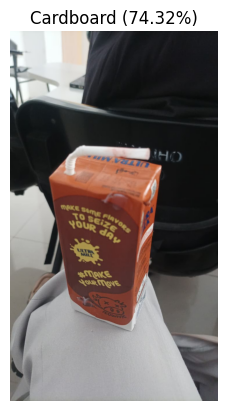

In [61]:
plt.imshow(img)
plt.axis("off")
plt.title(f"{predicted_class} ({confidence:.2f}%)")
plt.show()

Menampilkan probabilitas sembilan kategori

In [62]:
for i, kategori in enumerate(class_names):
    nilai = predictions[0][i] * 100
    print(f"{kategori}: {nilai:.2f}%")

Cardboard: 74.32%
Food Organics: 0.13%
Glass: 0.01%
Metal: 0.91%
Miscellaneous Trash: 1.57%
Paper: 2.70%
Plastic: 20.33%
Textile Trash: 0.00%
Vegetation: 0.02%


Visualisasi probabilitas prediksi

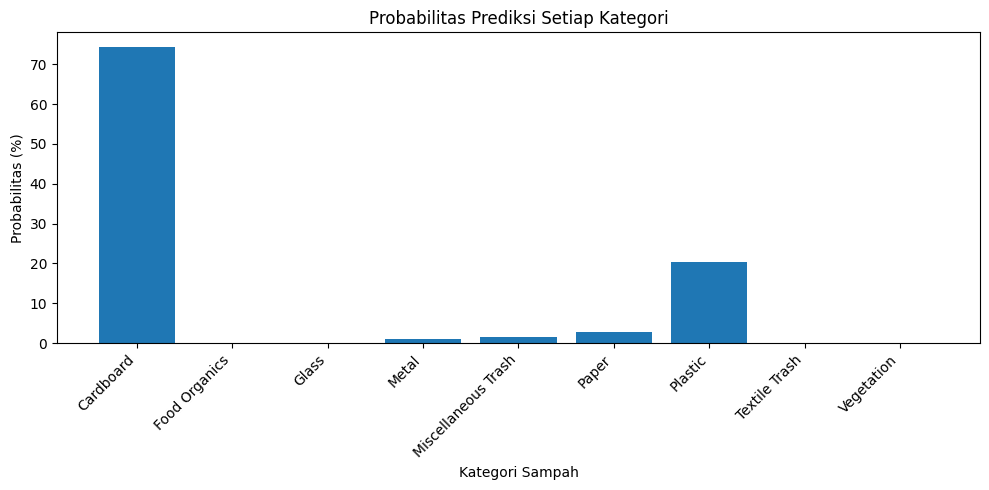

In [63]:
plt.figure(figsize=(10, 5))

plt.bar(class_names, predictions[0] * 100)

plt.title("Probabilitas Prediksi Setiap Kategori")
plt.xlabel("Kategori Sampah")
plt.ylabel("Probabilitas (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Menyimpan model final

In [64]:
model.save("waste_classifier.keras")

print("Model final berhasil disimpan.")

Model final berhasil disimpan.


Menyimpan nama kelas

In [38]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Nama kelas berhasil disimpan.")

Nama kelas berhasil disimpan.


Memeriksa file

In [39]:
import os

print("Model tersedia:", os.path.exists("waste_classifier.keras"))
print("Label tersedia:", os.path.exists("class_names.json"))

Model tersedia: True
Label tersedia: True


Membuat file aplikasi

In [40]:
%%writefile app.py
import streamlit as st
import tensorflow as tf
import numpy as np
import json
from PIL import Image

st.title("♻️ Klasifikasi Jenis Sampah")
st.write("Klasifikasi gambar sampah menggunakan MobileNetV2.")

@st.cache_resource
def load_model():
    return tf.keras.models.load_model("waste_classifier.keras")

model = load_model()

with open("class_names.json", "r") as f:
    class_names = json.load(f)

uploaded = st.file_uploader(
    "Unggah gambar sampah",
    type=["jpg", "jpeg", "png"]
)

if uploaded:
    img = Image.open(uploaded).convert("RGB")
    st.image(img, caption="Gambar yang diunggah")

    if st.button("Klasifikasikan"):
        resized = img.resize((224, 224))
        arr = np.array(resized, dtype=np.float32)
        arr = np.expand_dims(arr, axis=0)

        arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)

        result = model.predict(arr)[0]
        index = np.argmax(result)

        st.success(f"Kategori: {class_names[index]}")
        st.write(f"Confidence: {result[index]*100:.2f}%")

        st.subheader("Probabilitas Setiap Kategori")

        chart = {
            class_names[i]: float(result[i] * 100)
            for i in range(len(class_names))
        }

        st.bar_chart(chart)

Writing app.py


Membuat requirements.txt

In [41]:
%%writefile requirements.txt
streamlit
tensorflow
numpy
pillow

Writing requirements.txt


Memeriksa file aplikasi

In [42]:
for file in [
    "app.py",
    "requirements.txt",
    "waste_classifier.keras",
    "class_names.json"
]:
    print(file, ":", os.path.exists(file))

app.py : True
requirements.txt : True
waste_classifier.keras : True
class_names.json : True


Membuat ZIP aplikasi

In [43]:
import zipfile

nama_zip = "Aplikasi_Klasifikasi_Sampah.zip"

with zipfile.ZipFile(nama_zip, "w") as z:
    z.write("app.py")
    z.write("requirements.txt")
    z.write("waste_classifier.keras")
    z.write("class_names.json")

print("Aplikasi berhasil dikemas.")

Aplikasi berhasil dikemas.


Mengunduh aplikasi

In [44]:
files.download("Aplikasi_Klasifikasi_Sampah.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>